## Compute time vs. instance hardness (Lights Out, held-out instances)

LoopedActor counterpart of `Stoix/ramdp_experiments/analysis-compute_time-hardness.ipynb`.
Loads a trained Lights Out checkpoint from a `train.sh` run directory, rolls out its deterministic
policy (argmax action) on fresh instances, and for each episode records the initial and goal grids,
every step's grid, action and compute time (think iterations = `fp_iterations`), and whether it was solved.

Hardness is the puzzle's true shortest path between the two grids: the minimum number of presses,
solved exactly over GF(2). It is not the `dist` used to generate the goal, which is only an upper bound.
The analyses match the Stoix notebook:

1. first-step compute time vs. shortest path,
2. episode length vs. shortest path (the diagonal is optimal play),
3. per-step compute time vs. remaining shortest path from the current grid,
4. length to go vs. remaining shortest path,
5. compute time vs. chosen action (one-way ANOVA),

plus one analysis the Stoix notebook could not do:

6. **compute needed**: the readout of every pass c = 1..T is evaluated on each visited state, which gives
   the fewest passes after which the greedy press stays optimal. This separates "the model *needs* more
   compute on harder states" from "the halting policy *spends* more compute on them". That matters for
   `mem_halt` runs whose halting collapsed to always using the cap.

The model is rebuilt from the run's wandb `config.yaml`, so only `RUN_DIR` and `CHECKPOINT` need setting.
(The Stoix notebook's t-SNE section is not ported.)

In [1]:
%matplotlib inline
import glob
import os
import pickle
import sys
from argparse import Namespace
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from matplotlib.patches import Patch
from scipy import stats

# Run from the repo root (models/, envs/ and lightsout/eval_checkpoint.py import from there).
REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'lightsout' else Path.cwd()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))

from envs.lightsout_env import LightsOutEnv, default_config, press_matrix  # noqa: E402
from lightsout.eval_checkpoint import build_module  # noqa: E402
from utils import running_statistics  # noqa: E402

sns.set_palette('colorblind')
CI95_Z = 1.96  # normal-approximation 95% CI half-width, in units of SEM

In [2]:
# --- Run / checkpoint
RUN_DIR = 'exp/lightsout/mem_halt_nobh_gelu_bf16_ep2_gc0.999_s1'
CHECKPOINT = 'params_101.pkl'  # under <RUN_DIR>/checkpoints/<run name>/ (101 = the final evaluation)

# --- Rollout
NUM_EPISODES = 50000
BATCH = 5000
SEED = 0
# 'train': goals from the training distribution (dist in [1, threshold)), with the training episode length.
# 'eval': the held-out harder goals (dist in [threshold, M*N)), with the eval episode length.
INSTANCES = 'eval'
# fprm_mem_halt only: think time c = argmax p(c|s) ('mode', the training evaluation's choice) or c ~ p(c|s) ('sample').
HALT_MODE = 'mode'
# The rollout is cached under RUN_DIR; set True to recompute it, e.g. after changing the checkpoint.
FORCE_REROLLOUT = False
# Figures go to lightsout/figures/<run name>/<INSTANCES>/ (None = don't save).
FIG_DIR = Path('lightsout/figures') / Path(RUN_DIR).name / INSTANCES

### Model from the run's config

`build_module` (from `lightsout/eval_checkpoint.py`) rebuilds the architecture. Its arguments are read from
the wandb `config.yaml` that `ppo.py` writes into the run directory.

In [3]:
def load_run_config(run_dir):
    paths = sorted(glob.glob(os.path.join(run_dir, 'wandb', 'run-*', 'files', 'config.yaml')))
    assert paths, f'no wandb config.yaml under {run_dir}/wandb'
    raw = yaml.safe_load(open(paths[-1]))
    return {k: v['value'] for k, v in raw.items() if isinstance(v, dict) and 'value' in v and not k.startswith('_')}


def module_args(cfg, **overrides):
    """eval_checkpoint.build_module's arguments from a ppo.py config."""
    assert cfg.get('min_think_iters', 2) == 2, 'build_module assumes min_think_iters = 2'
    assert cfg.get('fprm_num_heads', 4) == 4, 'build_module assumes 4 heads'
    a = dict(
        arch=cfg['architecture'], max_iters=cfg['max_think_iters'], halt_kl=cfg['halt_kl'],
        rim_halt='latent' if cfg.get('halt_criterion') == 'latent_residual' else 'kl',
        halt_residual_thresh=cfg.get('halt_residual_thresh', 0.1),
        no_halt_beta_head=not cfg.get('halt_beta_head', True),
        thought_norm=cfg.get('cot_thought_norm', False),
        input_grid_conv=cfg.get('input_grid_conv', False), input_grid_conv_depth=cfg.get('input_grid_conv_depth', 1),
        perceiver_step_grid_conv=cfg.get('perceiver_step_grid_conv', False),
        perceiver_num_initial_latents=cfg.get('perceiver_num_initial_latents', 1),
        perceiver_cell_encoder_iters=cfg.get('perceiver_cell_encoder_iters', 0),
        num_blocks=cfg.get('num_blocks', 16), d_model=cfg['fprm_d_model'], num_layers=cfg['fprm_num_layers'],
        mlp_type=cfg['mlp_type'], mlp_round_to=cfg['mlp_round_to'], compute_dtype=cfg['compute_dtype'],
    )
    a.update(overrides)
    return Namespace(**a)


cfg = load_run_config(RUN_DIR)
ARCH = cfg['architecture']
GRID = cfg['env_id'].split('-', 1)[1]
M, N = (int(v) for v in GRID.split('x'))
MAX_ITERS = cfg['max_think_iters']
LOOPED = ARCH not in ('single_block', 'multi_block')

env_cfg = default_config()
env_cfg.m, env_cfg.n = M, N
env_cfg.difficulty_threshold = cfg['lightsout_difficulty_threshold']
env = LightsOutEnv(env_cfg)
EPISODE_LENGTH = cfg['lightsout_episode_length'] if INSTANCES == 'train' else (
    cfg['lightsout_eval_episode_length'] or cfg['lightsout_episode_length'])

ckpt_paths = glob.glob(os.path.join(RUN_DIR, 'checkpoints', '*', CHECKPOINT))
assert len(ckpt_paths) == 1, ckpt_paths
with open(ckpt_paths[0], 'rb') as f:
    policy_vars, norm = pickle.load(f)
if running_statistics.is_identity(norm):
    norm = None  # trained without observation normalization
mod = build_module(module_args(cfg), M, N)
print(f'{ARCH} on lightsout-{GRID}, cap {MAX_ITERS}, {INSTANCES} instances, episode length {EPISODE_LENGTH}')
print(f'checkpoint {ckpt_paths[0]}')

fprm_mem_halt on lightsout-5x4, cap 16, eval instances, episode length 20
checkpoint exp/lightsout/mem_halt_nobh_gelu_bf16_ep2_gc0.999_s1/checkpoints/lightsout-5x4__fprm_mem_halt__1__ppo__1792002978/params_101.pkl


### Shortest path between grids (GF(2) minimum-weight solve)

Pressing a cell toggles a fixed set of cells. Presses commute, and pressing a cell twice cancels out,
so reaching `goal` from `grid` means solving `press^T x = grid XOR goal (mod 2)` for a 0/1 press vector `x`.
The shortest path is the minimum Hamming weight of `x` over all solutions. There can be several when the
press matrix is singular (e.g. 5x5); 5x4 has full rank, so its solution is unique. The solver row-reduces
once, then solves a whole batch of right-hand sides with one matrix product plus a brute-force search
over the (small) kernel. It also returns the minimum-weight solution, which gives the optimal presses.

In [4]:
def gf2_prepare(A, max_kernel_dim=16):
    """Row-reduces the square GF(2) matrix A (A @ x = b). Returns (RREF, T, pivot_cols, kernel_basis, rank),
    with T @ A = RREF (mod 2)."""
    n = A.shape[0]
    Mx = np.concatenate([A.astype(np.uint8) % 2, np.eye(n, dtype=np.uint8)], axis=1)
    pivot_cols, row = [], 0
    for col in range(n):
        pivot = next((r for r in range(row, n) if Mx[r, col]), None)
        if pivot is None:
            continue
        Mx[[row, pivot]] = Mx[[pivot, row]]
        for r in range(n):
            if r != row and Mx[r, col]:
                Mx[r] ^= Mx[row]
        pivot_cols.append(col)
        row += 1
        if row == n:
            break
    RREF, T = Mx[:, :n], Mx[:, n:]
    free_cols = [c for c in range(n) if c not in pivot_cols]
    assert len(free_cols) <= max_kernel_dim, f'kernel dimension {len(free_cols)} too large to brute-force'
    kernel = []
    for fc in free_cols:
        v = np.zeros(n, np.uint8)
        v[fc] = 1
        for i, col in enumerate(pivot_cols):
            v[col] = RREF[i, fc]
        kernel.append(v)
    return RREF, T, pivot_cols, np.array(kernel, np.uint8).reshape(-1, n), row


def gf2_min_weight(prepared, diff):
    """diff [B, n] in {0, 1} -> (weight [B] float, NaN if infeasible; minimum-weight solution x [B, n])."""
    RREF, T, pivot_cols, kernel, rank = prepared
    diff = np.asarray(diff, np.uint8)
    rd = (diff @ T.T) % 2  # [B, n]
    feasible = ~np.any(rd[:, rank:], axis=1)
    x0 = np.zeros_like(diff)
    x0[:, pivot_cols] = rd[:, :len(pivot_cols)]
    best = x0.copy()
    best_w = x0.sum(1)
    for mask in range(1, 1 << len(kernel)):
        v = x0 ^ np.bitwise_xor.reduce(kernel[[i for i in range(len(kernel)) if mask >> i & 1]], axis=0)
        w = v.sum(1)
        better = w < best_w
        best[better], best_w[better] = v[better], w[better]
    return np.where(feasible, best_w, np.nan).astype(float), best


# press[i] = the cells toggled by pressing i, so grid' = grid + x @ press, i.e. press^T @ x = diff.
PRESS = np.asarray(press_matrix(M, N))
gf2 = gf2_prepare(PRESS.T)
print(f'press matrix rank {gf2[4]} / {M * N}, kernel dimension {len(gf2[3])}')

press matrix rank 20 / 20, kernel dimension 0


### Rollouts

The policy is deterministic (argmax action), as in the in-training evaluation. `fprm_mem_halt`'s think
time follows `HALT_MODE`. One jitted `lax.scan` per batch steps `BATCH` episodes for `EPISODE_LENGTH`
steps. Solved episodes freeze, and their remaining steps are flagged invalid.

In [5]:
def make_rollout(mod, params, norm, episode_length, instances, halt_mode):
    reset = env.reset if instances == 'train' else env.eval_reset

    def act(obs, goal, key):
        x = jnp.concatenate([obs, goal], axis=-1)
        kw = {'halt_key': key} if (ARCH == 'fprm_mem_halt' and halt_mode == 'sample') else {}
        (pi, _), inter = mod.apply(params, x, norm, mutable=['intermediates'], **kw)
        I = inter['intermediates']
        its = I['fp_iterations'][0] if 'fp_iterations' in I else jnp.ones(obs.shape[0], jnp.int32)
        return pi.mode(), its

    @jax.jit
    def rollout(keys):
        st = jax.vmap(reset)(keys)

        def step(carry, key):
            st, done = carry
            a, its = act(st.obs, st.info['target_goal'], key)
            nxt = jax.vmap(env.step)(st, a)
            out = (st.obs, a, its, ~done)
            new_st = jax.tree_util.tree_map(
                lambda n, o: jnp.where(done.reshape((-1,) + (1,) * (n.ndim - 1)), o, n), nxt, st)
            return (new_st, done | (nxt.done > 0.5)), out

        step_keys = jax.random.split(jax.random.fold_in(keys[0], 1), episode_length)
        (final, done), (grids, actions, its, valid) = jax.lax.scan(
            step, (st, jnp.zeros(keys.shape[0], bool)), step_keys)
        return (st.data.grid, st.data.goal, st.data.dist, done,
                jnp.swapaxes(grids, 0, 1), actions.T, its.T, valid.T)

    return rollout


cache = Path(RUN_DIR) / f'hardness_rollout-{Path(CHECKPOINT).stem}-{INSTANCES}-{HALT_MODE}-n{NUM_EPISODES}-seed{SEED}.pkl'
if cache.exists() and not FORCE_REROLLOUT:
    df = pd.read_pickle(cache)
    print(f'loaded {len(df)} episodes from {cache}')
else:
    rollout = make_rollout(mod, policy_vars, norm, EPISODE_LENGTH, INSTANCES, HALT_MODE)
    keys = jax.random.split(jax.random.PRNGKey(SEED), NUM_EPISODES)
    parts = [jax.device_get(rollout(keys[i:i + BATCH])) for i in range(0, NUM_EPISODES, BATCH)]
    init, goal, dist, solved, grids, actions, its, valid = (np.concatenate(p) for p in zip(*parts))
    spl, _ = gf2_min_weight(gf2, (init != goal))
    df = pd.DataFrame({
        'episode': np.arange(len(init)), 'initial_grid': list(init), 'goal_grid': list(goal), 'dist': dist,
        'shortest_path_length': spl, 'solved': solved, 'episode_length': valid.sum(1),
        'compute_time': (its * valid).sum(1) / valid.sum(1),  # mean per action, as the evaluator
        'states': list(grids), 'actions': list(actions), 'compute_times': list(its), 'valid_steps': list(valid),
    })
    df.to_pickle(cache)
    print(f'saved {len(df)} episodes to {cache}')

print(f'solved {df["solved"].mean():.3f}, mean compute time {df["compute_time"].mean():.2f}, '
      f'distinct (initial, goal) pairs {len(set(zip(map(bytes, df.initial_grid.map(lambda g: g.astype(np.uint8))), map(bytes, df.goal_grid.map(lambda g: g.astype(np.uint8))))))}')
print('generating dist vs. true shortest path:')
print(pd.crosstab(df['dist'], df['shortest_path_length']))

saved 50000 episodes to exp/lightsout/mem_halt_nobh_gelu_bf16_ep2_gc0.999_s1/hardness_rollout-params_101-eval-mode-n50000-seed0.pkl
solved 0.956, mean compute time 16.00, distinct (initial, goal) pairs 50000
generating dist vs. true shortest path:
shortest_path_length  10.0  11.0  12.0  13.0  14.0  15.0  16.0  17.0  18.0  \
dist                                                                         
10                    5022     0     0     0     0     0     0     0     0   
11                       0  5014     0     0     0     0     0     0     0   
12                       0     0  5017     0     0     0     0     0     0   
13                       0     0     0  4947     0     0     0     0     0   
14                       0     0     0     0  4910     0     0     0     0   
15                       0     0     0     0     0  5076     0     0     0   
16                       0     0     0     0     0     0  4932     0     0   
17                       0     0     0     0     0

In [6]:
def violin_mean_plot(x, y, xlabel, ylabel, title, fname=None, diagonal=False, dist_label='episode distribution'):
    """One violin per x value at its actual x position, plus the mean +/- 95% CI. Groups with fewer than
    2 points or no spread get no violin (the mean overlay still shows them)."""
    d = pd.DataFrame({'x': x, 'y': y}).dropna()
    by_x = d.groupby('x')['y'].agg(['mean', 'sem', 'count'])
    groups = [(k, g['y'].to_numpy()) for k, g in d.groupby('x')]
    groups = [(k, v) for k, v in groups if len(v) >= 2 and np.std(v) > 0]
    vcol, mcol = sns.color_palette('colorblind')[0], sns.color_palette('colorblind')[3]
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    if diagonal:
        lo, hi = min(d.x.min(), d.y.min()), max(d.x.max(), d.y.max())
        ax.plot([lo, hi], [lo, hi], '--', color='gray', lw=1.2, alpha=0.7, zorder=0)
    if groups:
        parts = ax.violinplot([v for _, v in groups], positions=[k for k, _ in groups], widths=0.8,
                              showmeans=False, showmedians=False, showextrema=False)
        for b in parts['bodies']:
            b.set_facecolor(vcol); b.set_edgecolor(vcol); b.set_alpha(0.4)
    eb = ax.errorbar(by_x.index, by_x['mean'], yerr=CI95_Z * by_x['sem'].fillna(0.0), marker='o', ms=4, lw=1.5,
                     color=mcol, label='mean ± 95% CI')
    handles = [Patch(facecolor=vcol, alpha=0.4, label=dist_label), eb]
    if diagonal:
        handles.append(plt.Line2D([], [], ls='--', color='gray', label='optimal'))
    ax.legend(handles=handles, fontsize=8)
    pr, sr = d.x.corr(d.y), d.x.corr(d.y, method='spearman')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(f'{title} (Pearson r={pr:.2f}, Spearman ρ={sr:.2f})', fontsize=9)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    if FIG_DIR is not None and fname:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / fname, bbox_inches='tight')
    plt.show()
    print(f'Pearson r = {pr:.3f}, Spearman rho = {sr:.3f}')
    return by_x


TAG = f'{ARCH} lightsout-{GRID} ({INSTANCES})'

### 1. First-step compute time vs. shortest path

The shortest path is the hardness at reset, so it is paired with the compute time of the first action,
the one taken while looking at `initial_grid`.

/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


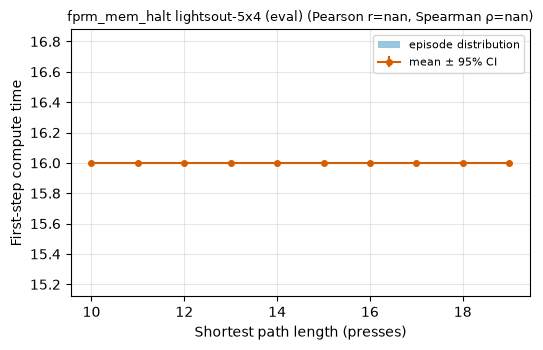

Pearson r = nan, Spearman rho = nan


In [7]:
_ = violin_mean_plot(df['shortest_path_length'], df['compute_times'].map(lambda c: c[0]),
                     'Shortest path length (presses)', 'First-step compute time', TAG,
                     'compute_time-hardness.pdf')

### 2. Episode length vs. shortest path

All episodes are included; unsolved ones run the full `EPISODE_LENGTH`. Points on the diagonal are optimal play.

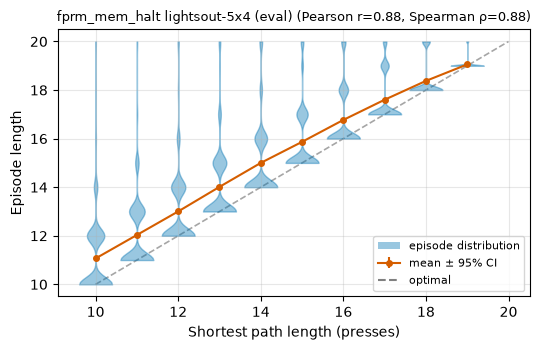

Pearson r = 0.883, Spearman rho = 0.884


In [8]:
_ = violin_mean_plot(df['shortest_path_length'], df['episode_length'], 'Shortest path length (presses)',
                     'Episode length', TAG, 'episode_length-hardness.pdf', diagonal=True)

## Per-step analyses

Every valid step of a solved episode becomes one row. Each row gets the shortest path from that step's
current grid to the goal, plus whether the press taken was optimal (whether it shortened the shortest path).

In [9]:
solved_df = df[df['solved']]
rows = []
for ep in solved_df.itertuples():
    v = ep.valid_steps
    k = int(v.sum())
    rows.append(pd.DataFrame({
        'episode': ep.episode, 'step': np.arange(k), 'action': ep.actions[:k], 'compute_time': ep.compute_times[:k],
        'length_to_go': ep.episode_length - np.arange(k),
    }).assign(_grid=list(ep.states[:k]), _goal=[ep.goal_grid] * k))
step_df = pd.concat(rows, ignore_index=True)
grids = np.stack(step_df.pop('_grid').to_numpy())
goals = np.stack(step_df.pop('_goal').to_numpy())
spl, sol = gf2_min_weight(gf2, grids != goals)
step_df['shortest_path_length'] = spl
step_df['optimal_press'] = sol[np.arange(len(sol)), step_df['action'].to_numpy()] == 1 if len(gf2[3]) == 0 else (
    gf2_min_weight(gf2, ((grids + PRESS[step_df['action'].to_numpy()]) % 2) != goals)[0] == spl - 1)
print(f'{len(step_df)} steps from {len(solved_df)} solved episodes; optimal presses {step_df["optimal_press"].mean():.3f}')

720248 steps from 47807 solved episodes; optimal presses 0.979


### 3. Per-step compute time vs. remaining shortest path

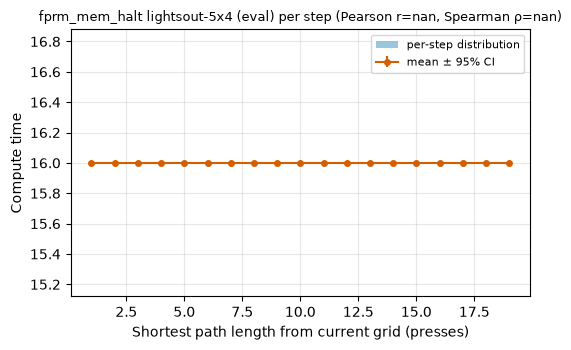

Pearson r = nan, Spearman rho = nan


In [10]:
_ = violin_mean_plot(step_df['shortest_path_length'], step_df['compute_time'],
                     'Shortest path length from current grid (presses)', 'Compute time', TAG + ' per step',
                     'compute_time-hardness_per_step.pdf', dist_label='per-step distribution')

### 4. Length to go vs. remaining shortest path

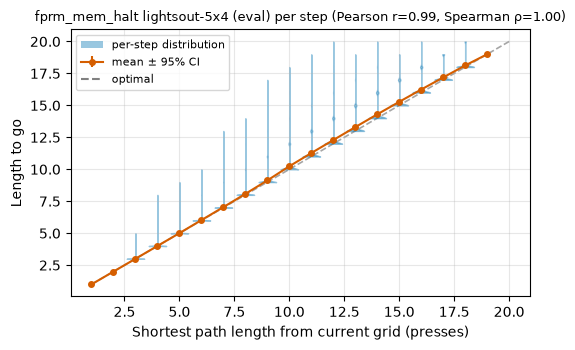

Pearson r = 0.994, Spearman rho = 0.996


In [11]:
_ = violin_mean_plot(step_df['shortest_path_length'], step_df['length_to_go'],
                     'Shortest path length from current grid (presses)', 'Length to go', TAG + ' per step',
                     'length_to_go-hardness_per_step.pdf', diagonal=True, dist_label='per-step distribution')

### 5. Compute time vs. chosen action

The action index has no order, so the Pearson/Spearman coefficients are only exploratory. The one-way
ANOVA effect size η² (the share of compute-time variance explained by which cell is pressed) is the
appropriate measure.

compute time is constant: no variance to explain


/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/bryanpu1/projects/iclr_2027/LoopedActor/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


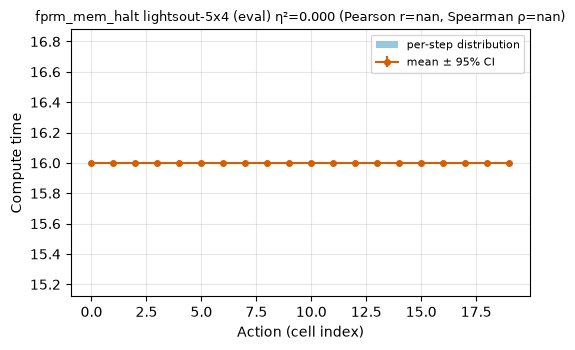

Pearson r = nan, Spearman rho = nan


In [12]:
groups = [g['compute_time'].to_numpy() for _, g in step_df.groupby('action')]
if np.var(step_df['compute_time']) > 0:
    f_stat, p_value = stats.f_oneway(*groups)
    gm = step_df['compute_time'].mean()
    eta2 = sum(len(g) * (g.mean() - gm) ** 2 for g in groups) / ((step_df['compute_time'] - gm) ** 2).sum()
    print(f'one-way ANOVA across actions: F = {f_stat:.3f}, p = {p_value:.3g}, eta^2 = {eta2:.4f}')
else:
    eta2 = 0.0
    print('compute time is constant: no variance to explain')
_ = violin_mean_plot(step_df['action'], step_df['compute_time'], 'Action (cell index)', 'Compute time',
                     TAG + f' η²={eta2:.3f}', 'compute_time-action.pdf', dist_label='per-step distribution')

## 6. Compute needed vs. hardness

Each visited state is re-read at every pass c = 1..T: `fprm_mem_halt` with its think time fixed to c;
other looped models rebuilt with cap c and halting off. The greedy press of pass c is checked for
optimality. Two quantities follow:

- **optimal-press rate** by pass and remaining shortest path: how much thinking a state of a given
  hardness needs;
- **compute needed**: the first pass from which the greedy press is optimal at every later pass up to T
  (T + 1 if pass T's press is not optimal).

If the compute needed grows with hardness while the halting policy (sections 1 and 3) spends a constant
amount, adaptive halting has room to save compute that the trained policy is not using.

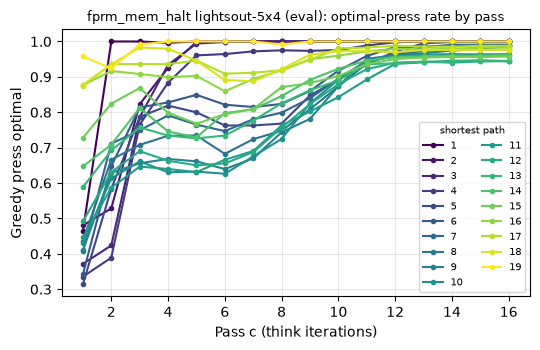

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
spl,,,,,,,,,,,,,,,,
1.0,0.464,1.000,1.000,0.996,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2.0,0.481,0.528,0.823,0.926,0.999,0.999,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
3.0,0.372,0.424,0.786,0.934,0.994,0.999,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
4.0,0.336,0.389,0.765,0.884,0.961,0.964,0.972,0.975,0.974,0.976,0.989,0.998,1.000,1.000,1.000,1.000
5.0,0.314,0.584,0.787,0.819,0.800,0.763,0.763,0.768,0.848,0.892,0.935,0.972,0.995,0.998,0.998,0.998
6.0,0.342,0.648,0.813,0.828,0.849,0.821,0.815,0.824,0.860,0.918,0.959,0.984,0.986,0.986,0.990,0.991
7.0,0.407,0.711,0.749,0.791,0.765,0.747,0.781,0.799,0.840,0.895,0.946,0.964,0.984,0.991,0.989,0.989
8.0,0.438,0.666,0.708,0.734,0.734,0.682,0.724,0.748,0.809,0.873,0.938,0.964,0.973,0.978,0.981,0.987
9.0,0.410,0.629,0.656,0.668,0.661,0.640,0.670,0.744,0.781,0.874,0.951,0.962,0.967,0.974,0.978,0.976


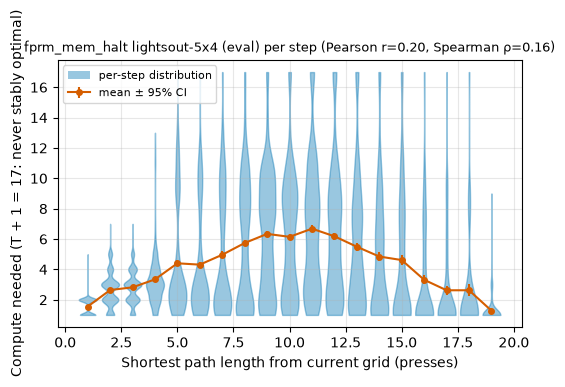

Pearson r = 0.199, Spearman rho = 0.158
mean compute spent 16.00 vs. needed 4.49; spent < needed on 0.021 of the states


In [13]:
NEED_SAMPLE = 20000  # visited states to re-read (sampled from the per-step rows)

if LOOPED:
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(step_df), size=min(NEED_SAMPLE, len(step_df)), replace=False)
    s_grid, s_goal, s_spl = grids[idx], goals[idx], spl[idx]
    x = jnp.asarray(np.concatenate([s_grid, s_goal], axis=-1), jnp.float32)

    def actions_at_pass(c):
        """Greedy press of pass c's readout for every sampled state."""
        if ARCH == 'fprm_mem_halt':
            m_c = mod
            kw = lambda b: {'halt_steps': jnp.full((b,), c, jnp.int32)}
        else:
            m_c = build_module(module_args(cfg, max_iters=c, halt_kl=-1.0, halt_residual_thresh=-1.0), M, N)
            kw = lambda b: {}
        f = jax.jit(lambda xb: m_c.apply(policy_vars, xb, norm, **kw(xb.shape[0]))[0].mode())
        return np.concatenate([np.asarray(f(x[i:i + BATCH])) for i in range(0, x.shape[0], BATCH)])

    passes = np.arange(1, MAX_ITERS + 1)
    acts = np.stack([actions_at_pass(int(c)) for c in passes], axis=1)  # [S, T]
    if len(gf2[3]) == 0:
        _, s_sol = gf2_min_weight(gf2, s_grid != s_goal)
        opt = np.take_along_axis(s_sol, acts, axis=1) == 1
    else:
        opt = np.stack([gf2_min_weight(gf2, ((s_grid + PRESS[acts[:, t]]) % 2) != s_goal)[0] == s_spl - 1
                        for t in range(MAX_ITERS)], axis=1)
    # first pass from which every later pass's press is optimal (T + 1 if pass T's is not)
    suffix_ok = np.flip(np.cumprod(np.flip(opt, 1), 1), 1).astype(bool)
    needed = np.where(suffix_ok.any(1), suffix_ok.argmax(1) + 1, MAX_ITERS + 1)

    rate = pd.DataFrame(opt, columns=passes).assign(spl=s_spl).groupby('spl').mean()
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    cmap = plt.get_cmap('viridis')
    for i, (k, r) in enumerate(rate.iterrows()):
        ax.plot(passes, r.values, marker='o', ms=3, color=cmap(i / max(len(rate) - 1, 1)), label=f'{int(k)}')
    ax.set_xlabel('Pass c (think iterations)'); ax.set_ylabel('Greedy press optimal')
    ax.set_title(f'{TAG}: optimal-press rate by pass', fontsize=9)
    ax.legend(title='shortest path', fontsize=7, title_fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    if FIG_DIR is not None:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / 'optimal_press-pass-hardness.pdf', bbox_inches='tight')
    plt.show()
    display(rate.round(3))

    _ = violin_mean_plot(s_spl, needed, 'Shortest path length from current grid (presses)',
                         f'Compute needed (T + 1 = {MAX_ITERS + 1}: never stably optimal)', TAG + ' per step',
                         'compute_needed-hardness_per_step.pdf', dist_label='per-step distribution')
    spent = step_df['compute_time'].to_numpy()[idx]
    print(f'mean compute spent {spent.mean():.2f} vs. needed {np.minimum(needed, MAX_ITERS).mean():.2f}; '
          f'spent < needed on {(spent < needed).mean():.3f} of the states')
else:
    print(f'{ARCH} has no think iterations to vary')